
# Task 5: Deep Learning Application in Data Science

## Project Title: Retail Sales Prediction Using Artificial Neural Network (ANN)

**Internship:** Virtual Data Science with Python

**Platform:** YuvaIntern

**Task:** Week 5 — Deep Learning Application in Data Science

**Project Domain:** Retail Sales Prediction

**Dataset:** Online Retail Dataset

**Learning Approach:** Supervised Deep Learning

**Problem Type:** Regression

**Deep Learning Framework:** TensorFlow / Keras

**Model:** Artificial Neural Network (ANN)

**Evaluation Metrics:** MAE, RMSE, and R²

## Objective

The objective of this project is to develop and evaluate an Artificial Neural Network using TensorFlow/Keras to predict retail sales from transaction-related features.

The project includes data preprocessing, feature engineering, neural network architecture design, model training, evaluation, visualization, and critical analysis of the results.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")


TensorFlow version: 2.21.0
All libraries imported successfully!


In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:

# Load the cleaned Online Retail dataset

df = pd.read_csv("online_retail_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Dataset shape: (536641, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.8+ MB


In [4]:

# Step 4: Data preprocessing

data = df.copy()

# Convert InvoiceDate to datetime
if "InvoiceDate" in data.columns:
    data["InvoiceDate"] = pd.to_datetime(
        data["InvoiceDate"], errors="coerce"
    )

# Remove cancelled invoices
if "InvoiceNo" in data.columns:
    data = data[
        ~data["InvoiceNo"].astype(str).str.startswith("C")
    ]

# Keep only positive quantities and unit prices
if "Quantity" in data.columns and "UnitPrice" in data.columns:
    data = data[
        (data["Quantity"] > 0) &
        (data["UnitPrice"] > 0)
    ]

# Create target variable
if "TotalSales" not in data.columns:
    data["TotalSales"] = (
        data["Quantity"] * data["UnitPrice"]
    )

# Remove rows with missing target
data = data.dropna(subset=["TotalSales"])

print("Original dataset rows:", len(df))
print("Rows after preprocessing:", len(data))
print("Missing target values:", data["TotalSales"].isna().sum())

print("\nTarget variable summary:")
display(data["TotalSales"].describe())

print("\nFirst five processed records:")
display(data.head())


Original dataset rows: 536641
Rows after preprocessing: 524878
Missing target values: 0

Target variable summary:


count    524878.000000
mean         20.275399
std         271.693566
min           0.001000
25%           3.900000
50%           9.920000
75%          17.700000
max      168469.600000
Name: TotalSales, dtype: float64


First five processed records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34


In [5]:

# Step 5: Feature Engineering

model_data = data.copy()

# Extract date-based features
if "InvoiceDate" in model_data.columns:
    model_data["InvoiceMonth"] = model_data["InvoiceDate"].dt.month
    model_data["InvoiceDay"] = model_data["InvoiceDate"].dt.day
    model_data["InvoiceWeekday"] = model_data["InvoiceDate"].dt.dayofweek
    model_data["InvoiceHour"] = model_data["InvoiceDate"].dt.hour

print("Feature engineering completed!")

print("\nAvailable columns:")
print(model_data.columns.tolist())

print("\nNew features preview:")
display(model_data.head())


Feature engineering completed!

Available columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalSales', 'InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday', 'InvoiceHour']

New features preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30,1.0,12.0,1.0,8.0
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0,8.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00,1.0,12.0,1.0,8.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0,8.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0,8.0


In [6]:

# Step 6: Select input features and target variable

candidate_features = [
    "InvoiceMonth",
    "InvoiceDay",
    "InvoiceWeekday",
    "InvoiceHour"
]

# Select features available in the dataset
features = [
    col for col in candidate_features
    if col in model_data.columns
]

if not features:
    raise ValueError(
        "No date-based features found. Check InvoiceDate."
    )

# Input features
X = model_data[features].copy()

# Target variable
y = model_data["TotalSales"].copy()

# Remove rows containing missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
valid_rows = X.notna().all(axis=1) & np.isfinite(y)

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Selected features:", features)
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput features preview:")
display(X.head())

print("\nTarget variable preview:")
display(y.head())


Selected features: ['InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday', 'InvoiceHour']
Input features shape: (225423, 4)
Target variable shape: (225423,)

Input features preview:


,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour
0,1.0,12.0,1.0,8.0
1,1.0,12.0,1.0,8.0
2,1.0,12.0,1.0,8.0
3,1.0,12.0,1.0,8.0
4,1.0,12.0,1.0,8.0



Target variable preview:


0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: TotalSales, dtype: float64

In [7]:

# Step 6: Select input features and target variable

candidate_features = [
    "InvoiceMonth",
    "InvoiceDay",
    "InvoiceWeekday",
    "InvoiceHour"
]

# Select features available in the dataset
features = [
    col for col in candidate_features
    if col in model_data.columns
]

if not features:
    raise ValueError(
        "No date-based features found. Check InvoiceDate."
    )

# Input features
X = model_data[features].copy()

# Target variable
y = model_data["TotalSales"].copy()

# Remove rows containing missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
valid_rows = X.notna().all(axis=1) & np.isfinite(y)

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Selected features:", features)
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput features preview:")
display(X.head())

print("\nTarget variable preview:")
display(y.head())


Selected features: ['InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday', 'InvoiceHour']
Input features shape: (225423, 4)
Target variable shape: (225423,)

Input features preview:


,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour
0,1.0,12.0,1.0,8.0
1,1.0,12.0,1.0,8.0
2,1.0,12.0,1.0,8.0
3,1.0,12.0,1.0,8.0
4,1.0,12.0,1.0,8.0



Target variable preview:


0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: TotalSales, dtype: float64

In [8]:

# Step 7: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Data split completed successfully!")

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)


Data split completed successfully!

Training features: (180338, 4)
Testing features: (45085, 4)

Training target: (180338,)
Testing target: (45085,)


In [9]:

# Step 8: Feature Scaling

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nFirst 5 scaled training rows:")
display(pd.DataFrame(
    X_train_scaled,
    columns=features
).head())


Feature scaling completed successfully!

Scaled training data shape: (180338, 4)
Scaled testing data shape: (45085, 4)

First 5 scaled training rows:


,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour
0,-1.398923,0.279976,-0.564321,-0.827699
1,-0.781658,-0.000548,0.456846,1.169673
2,0.144239,-0.561594,-0.564321,-0.028750
3,0.452872,1.121545,-0.053737,0.370724
4,1.378770,0.560499,-0.053737,0.370724


In [10]:

# Step 9: Build the Artificial Neural Network

from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

print("ANN model created successfully!")

model.summary()


ANN model created successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

# Step 10: Train the ANN model

history = model.fit(
    X_train_scaled,
    y_train.to_numpy(),
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    verbose=1
)

print("Model training completed!")


Epoch 1/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 202188.0312 - mae: 19.6524 - val_loss: 13464.5723 - val_mae: 20.1986
Epoch 2/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202118.5781 - mae: 20.3637 - val_loss: 13465.8750 - val_mae: 20.2297
Epoch 3/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202115.8281 - mae: 20.3672 - val_loss: 13469.2598 - val_mae: 20.6552
Epoch 4/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202115.8594 - mae: 20.3942 - val_loss: 13471.0625 - val_mae: 20.8169
Epoch 5/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202112.3281 - mae: 20.6649 - val_loss: 13474.5156 - val_mae: 20.9439
Epoch 6/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202112.8906 - mae: 20.6653 - val_loss: 13475.6445 - val_mae: 20.9838
Epoch 7/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202109.9688 - mae: 20.7349 - val_loss: 13476.9404 - val_mae: 21.0042
Epoch 8/20
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 202111.0469 - mae: 20.7150 - val_loss

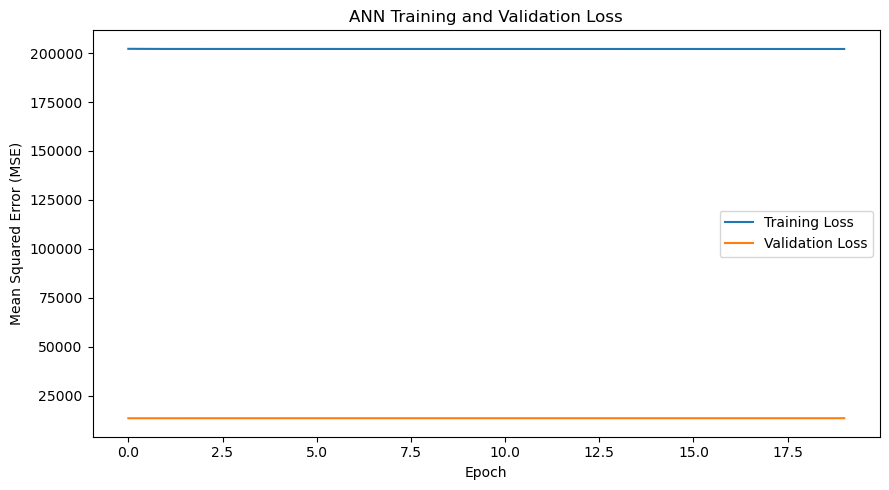

In [12]:

# Plot training and validation loss

plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [13]:

# Step 12: Evaluate the trained ANN model

y_pred = model.predict(X_test_scaled).flatten()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("ANN Model Evaluation Results")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")


1409/1409 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
ANN Model Evaluation Results
----------------------------------------
Mean Absolute Error (MAE): 20.6687
Root Mean Squared Error (RMSE): 194.6355
R-squared (R2): -0.0007


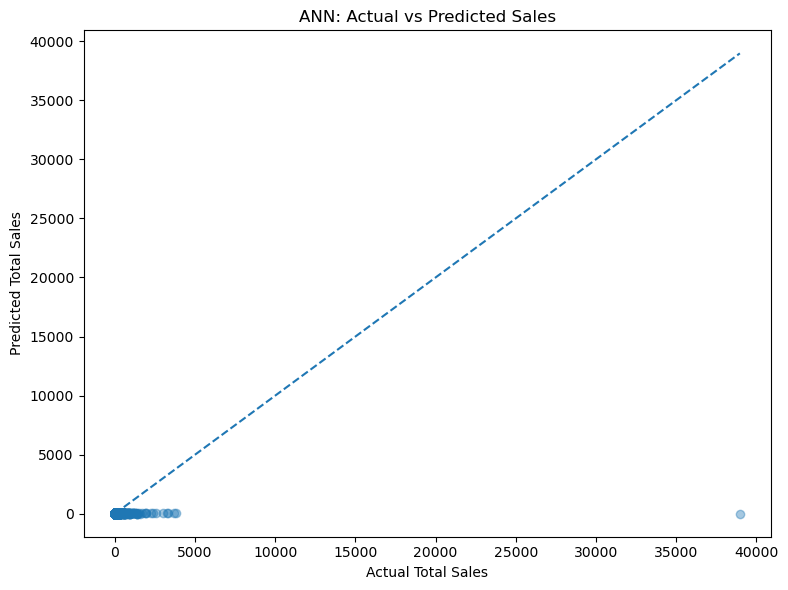

In [14]:

# Plot actual vs predicted sales

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Sales")
plt.ylabel("Predicted Total Sales")
plt.title("ANN: Actual vs Predicted Sales")
plt.tight_layout()
plt.show()


In [15]:

# Step 14: Create the model evaluation summary

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

display(results)

print("\nModel Summary:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")


,Metric,Value
0,MAE,20.668691
1,RMSE,194.635541
2,R2 Score,-0.000701



Model Summary:
MAE: 20.6687
RMSE: 194.6355
R2 Score: -0.0007


In [16]:

# Step 15: Save evaluation metrics

results.to_csv("task5_ann_evaluation_results.csv", index=False)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


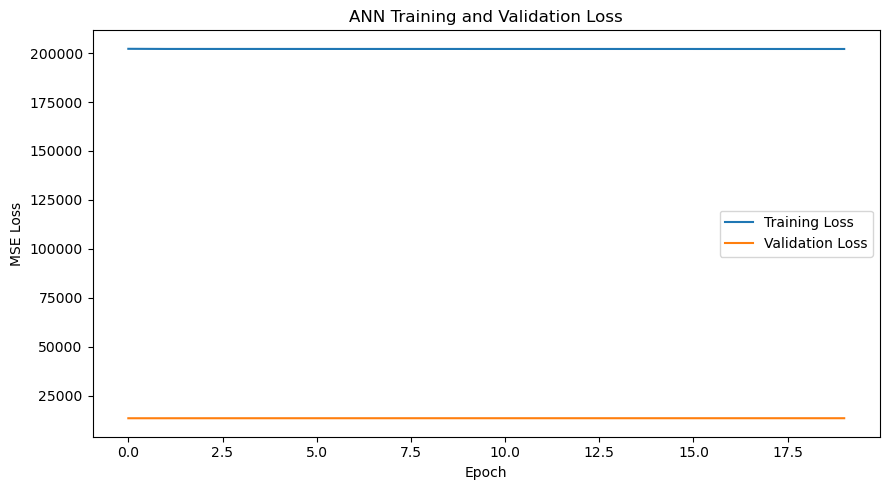

Training graph saved!


In [17]:

# Save training and validation loss graph

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.tight_layout()

plt.savefig("task5_training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

print("Training graph saved!")


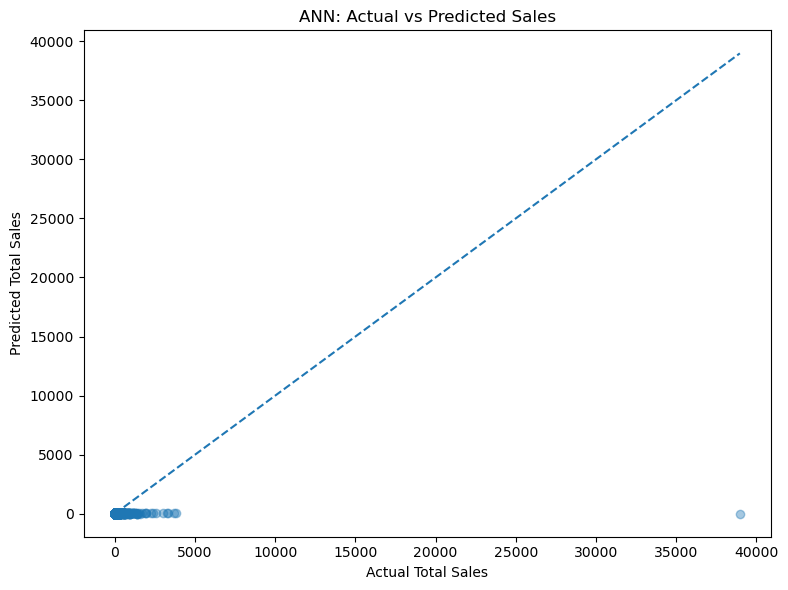

Prediction graph saved!


In [18]:

# Save actual vs predicted sales graph

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Sales")
plt.ylabel("Predicted Total Sales")
plt.title("ANN: Actual vs Predicted Sales")
plt.tight_layout()

plt.savefig("task5_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

print("Prediction graph saved!")
